# Signal Before Scouting
### A reliability-first framework for linking Combine tracking data to NFL performance

**NFL Big Data Bowl 2027 — analysis notebook (companion to the writeup)**

Teams now receive 10 Hz sensor data for every Combine rep. Before any of it can predict NFL performance, it has to clear a simpler bar: **does the same player produce the same number twice?** This notebook:

1. Measures how **repeatable** Combine tracking metrics are (rep 1 vs rep 2), and how repeatable the NFL outcomes they should predict are (split-half).
2. Tests three Combine → NFL links, each against its **reliability ceiling** (the largest correlation that is mathematically possible):
   * **40-yard dash peak speed → NFL in-game top speed** (all positions)
   * **Pass-rush drill burst → NFL get-off** (defensive line)
   * **Route-drill cut efficiency → NFL separation over expected** (wide receivers)
3. Turns the results into a **"reps needed" table** that tells evaluators which tracking metrics they can trust from a single rep.

Sections: **0** Setup · **A** 40-yard dash · **B** Defensive line · **C** Wide receivers · **D** NFL game speed · **R1–R4** Results & figures · **Appendix**

## 0. Setup

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
warnings.filterwarnings("ignore")

DATA_DIR = "/kaggle/input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027"
OUT_DIR = "/kaggle/working/figs"
os.makedirs(OUT_DIR, exist_ok=True)
YDS_TO_MPH = 2.04545
SEED = 42

# ---- chart style (one consistent look for every figure) ----
COL = {"surface": "#fcfcfb", "ink": "#0b0b0b", "ink2": "#52514e", "grid": "#e4e3df",
     "combine": "#2a78d6", "nfl": "#eb6834", "ref": "#a3a29c"}
plt.rcParams.update({
    "figure.facecolor": COL["surface"], "axes.facecolor": COL["surface"], "savefig.facecolor": COL["surface"],
    "axes.edgecolor": COL["grid"], "axes.labelcolor": COL["ink2"], "xtick.color": COL["ink2"], "ytick.color": COL["ink2"],
    "text.color": COL["ink"], "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COL["grid"], "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
})

# ---- statistics helpers ----
def spearman_brown(r, k=2):
    # reliability of an average of k measurements, given single-measurement correlation r
    return k * r / (1 + (k - 1) * r) if np.isfinite(r) and r > -1 / (k - 1 + 1e-9) else np.nan

def reps_needed(r, target=0.7):
    # how many reps must be averaged to reach the target reliability
    return target * (1 - r) / (r * (1 - target)) if r > 0 else np.inf

def z_within(df, col, by):
    # z-score inside groups (position, drill...), so groups are compared fairly
    return df.groupby(by)[col].transform(lambda v: (v - v.mean()) / v.std())

def rep_reliability(reps, id_cols, value_col, order_cols):
    # rep 1 vs rep 2 correlation for the same player (and same drill)
    r = reps.sort_values(order_cols).copy()
    r["rep_no"] = r.groupby(id_cols).cumcount()
    p = r[r["rep_no"] < 2].pivot_table(index=id_cols, columns="rep_no", values=value_col).dropna()
    if len(p) < 10:
        return np.nan, len(p)
    return p[0].corr(p[1], method="spearman"), len(p)

def split_half(df, id_col, val_col, agg="mean", min_n=30, unit_col=None, seed=SEED):
    # random split of each player's plays (or games) into two halves -> Spearman-Brown reliability
    d = df[[id_col, val_col] + ([unit_col] if unit_col else [])].dropna(subset=[val_col]).copy()
    d = d[d.groupby(id_col)[val_col].transform("size") >= min_n]
    rng = np.random.default_rng(seed)
    if unit_col:
        units = d[unit_col].unique()
        d["half"] = d[unit_col].map(dict(zip(units, rng.integers(0, 2, len(units)))))
    else:
        d["half"] = rng.integers(0, 2, len(d))
    m = d.groupby([id_col, "half"])[val_col].agg(agg).unstack().dropna()
    r = m[0].corr(m[1], method="spearman")
    return r, spearman_brown(r), len(m)

def boot_r(x, y, n=2000, seed=SEED):
    # rank (Spearman) correlation with a 95% bootstrap interval
    x, y = stats.rankdata(x), stats.rankdata(y)
    rng = np.random.default_rng(seed)
    rs = [np.corrcoef(x[i], y[i])[0, 1] for i in (rng.integers(0, len(x), len(x)) for _ in range(n))]
    return np.corrcoef(x, y)[0, 1], np.nanpercentile(rs, 2.5), np.nanpercentile(rs, 97.5)

RELIABILITY = []   # rows for the reliability atlas
LINKS = []         # rows for the ceiling chart
RESULTS = {}       # headline numbers for the writeup

In [2]:
players = pd.read_csv(f"{DATA_DIR}/players.csv")
combine = pd.read_csv(f"{DATA_DIR}/combine_results.csv")
trk = pd.read_csv(f"{DATA_DIR}/combine_tracking.csv")
plays = pd.read_csv(f"{DATA_DIR}/player_play.csv", low_memory=False)
trk = trk[trk["entity_type"] == "PLAYER"].copy()
trk["time"] = pd.to_datetime(trk["time"], utc=True, format="ISO8601")
print("players:", len(players), "| combine tracking rows:", len(trk), "| NFL player-plays:", len(plays))

players: 510 | combine tracking rows: 431094 | NFL player-plays: 314197


## A. The 40-yard dash: what the stopwatch time hides

The official 40 time blends *how fast a player gets going* with *how fast he can go*. Tracking separates them. For each rep we measure:

* **peak speed**: the fastest 0.1 s reading in the rep
* **t_10 / t_20 / t_40**: time from first movement (speed > 0.5 yd/s) to 10, 20 and 40 yards, interpolated between frames

We then check them against the official stopwatch and measure how repeatable each one is.

In [3]:
f = trk[trk["drill_name"] == "FORTY_YARD_DASH"].sort_values(["nfl_id", "event_id", "attempt", "time"])

def time_to(cum, rel, d):
    i = np.where(cum >= d)[0]
    if len(i) == 0 or i[0] == 0:
        return np.nan
    j = i[0]
    frac = (d - cum[j - 1]) / max(cum[j] - cum[j - 1], 1e-9)
    return rel[j - 1] + frac * (rel[j] - rel[j - 1])

F_EMPTY = pd.Series({k: np.nan for k in ["peak_speed", "t_10", "t_20", "t_40"]})
def forty_rep(g):
    s = g["s"].to_numpy()
    sec = (g["time"] - g["time"].iloc[0]).dt.total_seconds().to_numpy()
    mv = np.where(s > 0.5)[0]
    if len(mv) == 0 or len(g) < 30:
        return F_EMPTY
    i0 = mv[0]
    rel = sec[i0:] - sec[i0]
    x, y = g["x"].to_numpy()[i0:], g["y"].to_numpy()[i0:]
    cum = np.r_[0, np.cumsum(np.hypot(np.diff(x), np.diff(y)))]
    run = s[i0:][cum <= 45]                       # ignore the slow-down after the finish
    run = run[run < 12.5]                          # drop sensor glitches (> 25 mph)
    return pd.Series({"peak_speed": run.max() if len(run) else np.nan,
                      "t_10": time_to(cum, rel, 10), "t_20": time_to(cum, rel, 20), "t_40": time_to(cum, rel, 40)})

frep = (f.groupby(["nfl_id", "event_id", "attempt"]).apply(forty_rep, include_groups=False)
          .reset_index().dropna(subset=["peak_speed"]))
f40 = frep.groupby("nfl_id")[["peak_speed", "t_10", "t_20", "t_40"]].mean().reset_index()
f40["n_reps"] = frep.groupby("nfl_id").size().values
print("40-yd reps:", len(frep), "| players:", len(f40), "| median reps per player:", f40["n_reps"].median())

chk = f40.merge(combine[["nfl_id", "ten_yd_split", "forty"]], on="nfl_id")
RESULTS["t40_vs_official_r"] = round(chk["t_40"].corr(chk["forty"]), 3)
RESULTS["t10_vs_official_r"] = round(chk["t_10"].corr(chk["ten_yd_split"]), 3)
print("Tracking t_40 vs official forty r =", RESULTS["t40_vs_official_r"])
print("Tracking t_10 vs official 10-yd split r =", RESULTS["t10_vs_official_r"])

for col, label in [("peak_speed", "40: peak speed"), ("t_40", "40: time to 40 yd"),
                   ("t_20", "40: time to 20 yd"), ("t_10", "40: time to 10 yd")]:
    r, n = rep_reliability(frep, ["nfl_id"], col, ["nfl_id", "event_id", "attempt"])
    RELIABILITY.append({"side": "Combine", "measure": label, "single_rep_r": r, "pairs": n,
                        "reliability": spearman_brown(r, 2)})   # players' value = mean of ~2 reps
pd.DataFrame(RELIABILITY).round(3)

40-yd reps: 793 | players: 418 | median reps per player: 2.0
Tracking t_40 vs official forty r = 0.877
Tracking t_10 vs official 10-yd split r = 0.395


,side,measure,single_rep_r,pairs,reliability
0,Combine,40: peak speed,0.981,375,0.990
1,Combine,40: time to 40 yd,0.823,259,0.903
2,Combine,40: time to 20 yd,0.708,375,0.829
3,Combine,40: time to 10 yd,0.562,375,0.719


## B. Defensive line: pass-rush drill burst → NFL get-off

**Combine side:** in `PASS_RUSH_DRILL`, distance covered in the first second after movement starts, and time to cover 3 yards.

**NFL side:** `player_get_off` from `player_play.csv` (seconds, lower = faster). We drop impossible values (< 0.3 s) and the 2.0 s cap, and use each player's **median** over pass-rush snaps (minimum 50 snaps).

Edge rushers (DE/OLB) and interior linemen (DT/NT) do different jobs, so every comparison is made **within role**.

In [4]:
dl_ids = combine.loc[combine["combine_position"] == "DL", "nfl_id"]
t_dl = trk[trk["nfl_id"].isin(dl_ids) & (trk["drill_name"] == "PASS_RUSH_DRILL")].sort_values(
    ["nfl_id", "event_id", "attempt", "time"])

B_EMPTY = pd.Series({"dist_1s": np.nan, "t_3yd": np.nan})
def burst_rep(g):
    s = g["s"].to_numpy()
    sec = (g["time"] - g["time"].iloc[0]).dt.total_seconds().to_numpy()
    mv = np.where(s > 0.5)[0]
    if len(mv) == 0:
        return B_EMPTY
    rel = sec - sec[mv[0]]
    step = np.r_[0, np.hypot(np.diff(g["x"].to_numpy()), np.diff(g["y"].to_numpy()))]
    w = (rel >= 0) & (rel <= 1.0)
    cum = np.cumsum(np.where(rel >= 0, step, 0))
    return pd.Series({"dist_1s": step[w].sum(), "t_3yd": time_to(cum, rel, 3.0)})

dl_rep = (t_dl.groupby(["nfl_id", "event_id", "attempt"]).apply(burst_rep, include_groups=False)
            .reset_index().dropna(subset=["dist_1s"]))
for col, label in [("dist_1s", "DL drill: distance in 1st second"), ("t_3yd", "DL drill: time to 3 yd")]:
    r, n = rep_reliability(dl_rep, ["nfl_id"], col, ["nfl_id", "event_id", "attempt"])
    RELIABILITY.append({"side": "Combine", "measure": label, "single_rep_r": r, "pairs": n,
                        "reliability": spearman_brown(r, 2)})
burst = dl_rep.groupby("nfl_id")[["dist_1s", "t_3yd"]].mean().reset_index()

# NFL get-off and pressure
rush = plays[plays["nfl_id"].isin(dl_ids) & plays["player_get_off"].between(0.3, 1.99)].copy()
r_go, rel_go, n_go = split_half(rush, "nfl_id", "player_get_off", agg="median", min_n=50)
RELIABILITY.append({"side": "NFL", "measure": "NFL: DL get-off", "single_rep_r": np.nan,
                    "pairs": n_go, "reliability": rel_go})
dl_nfl = (rush.groupby("nfl_id")
              .agg(snaps=("player_get_off", "size"), get_off=("player_get_off", "median"),
                   pressure_rate=("time_to_pressure", lambda v: v.notna().mean()))
              .reset_index())
dl_nfl = dl_nfl[dl_nfl["snaps"] >= 50]

EDGE = ["DE", "OLB", "EDGE"]
dl = (dl_nfl.merge(burst, on="nfl_id")
            .merge(players[["nfl_id", "nfl_position"]], on="nfl_id"))
dl["role"] = np.where(dl["nfl_position"].isin(EDGE), "Edge", "Interior")
dl["burst_z"] = z_within(dl, "dist_1s", "role")
dl["quick_z"] = -z_within(dl, "get_off", "role")          # positive = faster get-off
dl = dl.dropna(subset=["burst_z", "quick_z"])
r, lo, hi = boot_r(dl["burst_z"], dl["quick_z"])
rel_burst = [x["reliability"] for x in RELIABILITY if x["measure"] == "DL drill: distance in 1st second"][0]
LINKS.append({"link": "DL drill burst → NFL get-off", "n": len(dl), "r": r, "lo": lo, "hi": hi,
              "ceiling": np.sqrt(max(rel_burst, 0) * max(rel_go, 0))})
for role, g in dl.groupby("role"):
    rr, pp = stats.spearmanr(g["dist_1s"], -g["get_off"])
    print(f"{role:9s} n={len(g):3d}  Spearman(burst, get-off quickness) = {rr:+.3f}  p = {pp:.3f}")
print(f"Pooled within-role r = {r:+.3f}  (95% CI {lo:+.3f} to {hi:+.3f})")

Edge      n= 57  Spearman(burst, get-off quickness) = +0.128  p = 0.341
Interior  n= 46  Spearman(burst, get-off quickness) = -0.046  p = 0.763
Pooled within-role r = +0.028  (95% CI -0.161 to +0.229)


## C. Wide receivers: route-drill cuts → NFL separation over expected

**Combine side:** in every breaking-route drill (curl, comeback, slant, out, dagger…) we find the cut: the largest change of running direction over ±0.3 s, counted only while the receiver is running before (> 3 yd/s) and after (> 2.5 yd/s) it. This ignores the slow-down after the catch. At the cut we measure:
* **speed retention**: lowest speed at the cut ÷ entry speed
* **re-acceleration**: speed gained in the 0.5 s after the cut
* **break time**: seconds spent below 70 % of entry speed

Drill names change between years (e.g. `SPEED_OUT_LEFT` vs `SPEED_OUT_ROUTE_LEFT`), so every metric is z-scored **within drill and year**. The **break score** averages the three.

**NFL side:** *Separation over expected (SOE)*: separation at the throw minus the separation expected for that route type, coverage (man/zone) and pass depth. Go routes have no cut, so they serve as a **placebo**.

In [5]:
wr_ids = combine.loc[combine["combine_position"] == "WR", "nfl_id"]
ROUTE_KEYS = ["ROUTE", "CURL", "COMEBACK", "SLANT", "DAGGER", "SPEED_OUT", "SAIL", "STRIKE", "CORNER"]
NO_BREAK = ["GO_ROUTE", "FADE"]
break_drills = sorted(d for d in trk["drill_name"].unique()
                      if any(k in d for k in ROUTE_KEYS) and not any(k in d for k in NO_BREAK))
t_wr = trk[trk["nfl_id"].isin(wr_ids) & trk["drill_name"].isin(break_drills)].sort_values(
    ["nfl_id", "drill_name", "event_id", "attempt", "time"])

W_KEYS = ["break_frame", "turn_deg", "entry_speed", "speed_retention", "reaccel", "break_time"]
W_EMPTY = pd.Series({k: np.nan for k in W_KEYS})
def break_rep(g):
    g = g.reset_index(drop=True)
    s = g["s"].to_numpy()
    if len(g) < 25:
        return W_EMPTY
    x = g["x"].rolling(3, center=True, min_periods=1).mean().to_numpy()
    y = g["y"].rolling(3, center=True, min_periods=1).mean().to_numpy()
    vx, vy = np.gradient(x), np.gradient(y)
    running = np.where(s > 4.0)[0]
    if len(running) == 0:
        return W_EMPTY
    L, turn = 3, np.full(len(g), np.nan)
    for i in range(max(running[0], L), len(g) - L):
        if s[i - L] < 3.0 or s[i + L] < 2.5:
            continue
        a1, a2 = np.arctan2(vy[i - L], vx[i - L]), np.arctan2(vy[i + L], vx[i + L])
        turn[i] = np.degrees(abs(np.angle(np.exp(1j * (a2 - a1)))))
    if np.all(np.isnan(turn)) or np.nanmax(turn) < 25:
        return W_EMPTY
    b = int(np.nanargmax(turn))
    entry = s[max(0, b - 10): b + 1].max()
    low = s[max(0, b - 3): b + 4].min()
    win = s[max(0, b - 10): b + 11]
    return pd.Series({"break_frame": b, "turn_deg": np.nanmax(turn), "entry_speed": entry,
                      "speed_retention": low / entry if entry > 0 else np.nan,
                      "reaccel": (s[min(len(s) - 1, b + 5)] - low) / 0.5,
                      "break_time": (win < 0.7 * entry).sum() * 0.1})

wr_rep = (t_wr.groupby(["nfl_id", "draft_year", "drill_name", "event_id", "attempt"])
              .apply(break_rep, include_groups=False).reset_index().dropna(subset=["turn_deg"]))
for c in ["entry_speed", "turn_deg", "speed_retention", "reaccel", "break_time"]:
    wr_rep[c + "_z"] = z_within(wr_rep, c, ["drill_name", "draft_year"])
wr_rep["break_score"] = (wr_rep["speed_retention_z"] + wr_rep["reaccel_z"] - wr_rep["break_time_z"]) / 3
print("Breaking-route reps with a detected cut:", len(wr_rep), "| WRs:", wr_rep["nfl_id"].nunique())
print(wr_rep.groupby("drill_name").agg(reps=("turn_deg", "size"), median_turn_deg=("turn_deg", "median"),
                                        median_retention=("speed_retention", "median")).round(2))

for col, label in [("break_time_z", "WR cut: break time"), ("entry_speed_z", "WR cut: entry speed"),
                   ("speed_retention_z", "WR cut: speed retention"), ("turn_deg_z", "WR cut: turn angle"),
                   ("reaccel_z", "WR cut: re-acceleration")]:
    r, n = rep_reliability(wr_rep, ["nfl_id", "drill_name"], col, ["nfl_id", "drill_name", "event_id", "attempt"])
    RELIABILITY.append({"side": "Combine", "measure": label, "single_rep_r": r, "pairs": n,
                        "reliability": r})                  # one rep per drill is the norm

# player-level break score: split each player's reps into two halves
wr_rep = wr_rep.sort_values(["nfl_id", "drill_name", "event_id", "attempt"])
wr_rep["half"] = wr_rep.groupby("nfl_id").cumcount() % 2
hb = wr_rep.groupby(["nfl_id", "half"])["break_score"].mean().unstack().dropna()
r_bs = hb[0].corr(hb[1], method="spearman")
RELIABILITY.append({"side": "Combine", "measure": "WR cut: break score (all drills)", "single_rep_r": np.nan,
                    "pairs": len(hb), "reliability": spearman_brown(r_bs)})
brk = wr_rep.groupby("nfl_id").agg(break_score=("break_score", "mean"), n_reps=("break_score", "size")).reset_index()
brk = brk[brk["n_reps"] >= 2]

# NFL separation over expected
tg = plays[plays["nfl_id"].isin(wr_ids) & plays["separation_at_pass_forward"].notna()
           & plays["route_ran"].notna()].copy()
tg["coverage"] = tg["team_coverage_man_zone"].fillna("UNK").astype(str)
tg["depth"] = pd.cut(tg["pass_length"], [-99, 0, 5, 10, 20, 99]).astype(str)
exp_fit = smf.ols("separation_at_pass_forward ~ C(route_ran) + C(coverage) + C(depth)", data=tg).fit()
tg["soe"] = tg["separation_at_pass_forward"] - exp_fit.fittedvalues
tg["route_group"] = np.where(tg["route_ran"].astype(str).str.upper().isin(["GO", "FADE"]), "vertical", "breaking")
print(f"Expected-separation model R2 = {exp_fit.rsquared:.3f} on {len(tg):,} targets")

r_soe, rel_soe, n_soe = split_half(tg[tg["route_group"] == "breaking"], "nfl_id", "soe", min_n=30)
RELIABILITY.append({"side": "NFL", "measure": "NFL: WR separation over expected", "single_rep_r": np.nan,
                    "pairs": n_soe, "reliability": rel_soe})
r_sep, rel_sep, n_sep = split_half(tg, "nfl_id", "separation_at_pass_forward", min_n=30)
RELIABILITY.append({"side": "NFL", "measure": "NFL: WR raw separation", "single_rep_r": np.nan,
                    "pairs": n_sep, "reliability": rel_sep})

soe = (tg.groupby(["nfl_id", "route_group"]).agg(targets=("soe", "size"), soe=("soe", "mean"))
         .reset_index().query("targets >= 15")
         .pivot(index="nfl_id", columns="route_group", values="soe").reset_index())
wr = brk.merge(soe, on="nfl_id")
for outcome in ["breaking", "vertical"]:
    d = wr.dropna(subset=[outcome])
    r, lo, hi = boot_r(d["break_score"], d[outcome])
    print(f"Break score vs SOE ({outcome:8s} routes): r = {r:+.3f}  95% CI {lo:+.3f} to {hi:+.3f}  n = {len(d)}")
    if outcome == "breaking":
        LINKS.append({"link": "WR cut skill → NFL separation", "n": len(d), "r": r, "lo": lo, "hi": hi,
                      "ceiling": np.sqrt(max(spearman_brown(r_bs), 0) * max(rel_soe, 0))})

Breaking-route reps with a detected cut: 830 | WRs: 107
                         reps  median_turn_deg  median_retention
drill_name                                                      
CIRCUS_ROUTE_LEFT          42            30.48              0.90
COMEBACK_ROUTE_RIGHT      101            70.03              0.44
CURL_ROUTE_RIGHT          100            82.90              0.37
DAGGER_ROUTE_LEFT         115            33.82              0.85
POST_CORNER_ROUTE_LEFT     78            33.15              0.87
POST_CORNER_ROUTE_RIGHT    28            28.19              0.96
SLANT_ROUTE_LEFT           54            27.67              0.87
SLOT_SAIL_ROUTE_RIGHT     103            36.78              0.90
SLOT_STRIKE_ROUTE_LEFT     85            30.28              0.96
SPEED_OUT_LEFT             37            37.89              0.91
SPEED_OUT_ROUTE_LEFT       87            39.33              0.86
Expected-separation model R2 = 0.194 on 38,030 targets
Break score vs SOE (breaking routes): r = +0

## D. NFL in-game top speed (2023–2025 game tracking)

For every player and play we take the maximum speed (readings above 25 mph are treated as glitches). A player's **game top speed** is the mean of his 10 fastest plays (minimum 100 plays). Its reliability is measured by splitting **games** at random into two halves.

*This step reads about 2 GB in chunks and takes several minutes.*

In [6]:
ids = set(f40["nfl_id"])
parts = []
for yr in [2023, 2024, 2025]:
    for ch in pd.read_csv(f"{DATA_DIR}/game_tracking_{yr}.csv", usecols=["game_id", "play_id", "nfl_id", "s"],
                          chunksize=3_000_000):
        ch = ch[ch["nfl_id"].isin(ids) & (ch["s"] < 12.5)]
        parts.append(ch.groupby(["nfl_id", "game_id", "play_id"])["s"].max())
    print("read", yr)
play_max = pd.concat(parts).groupby(level=[0, 1, 2]).max().reset_index(name="play_max_s")

TOP_N = 10
top_speed = lambda v: np.sort(np.asarray(v))[-TOP_N:].mean()
game = play_max.groupby("nfl_id").agg(plays=("play_max_s", "size"), game_top=("play_max_s", top_speed)).reset_index()
game = game[game["plays"] >= 100]
r_gs, rel_gs, n_gs = split_half(play_max[play_max["nfl_id"].isin(game["nfl_id"])], "nfl_id", "play_max_s",
                                agg=top_speed, min_n=1, unit_col="game_id")
RELIABILITY.append({"side": "NFL", "measure": "NFL: game top speed", "single_rep_r": np.nan,
                    "pairs": n_gs, "reliability": rel_gs})
print(f"Players with >= 100 plays: {len(game)} | game top speed reliability = {rel_gs:.3f}")

read 2023
read 2024
read 2025
Players with >= 100 plays: 336 | game top speed reliability = 0.971


## R1. Reliability atlas: which numbers can be trusted?

Reliability is the (rank) correlation you would get between two independent measurements of the same player (0 = pure noise, 1 = perfectly repeatable). A common working threshold for decisions about individuals is **0.70**.

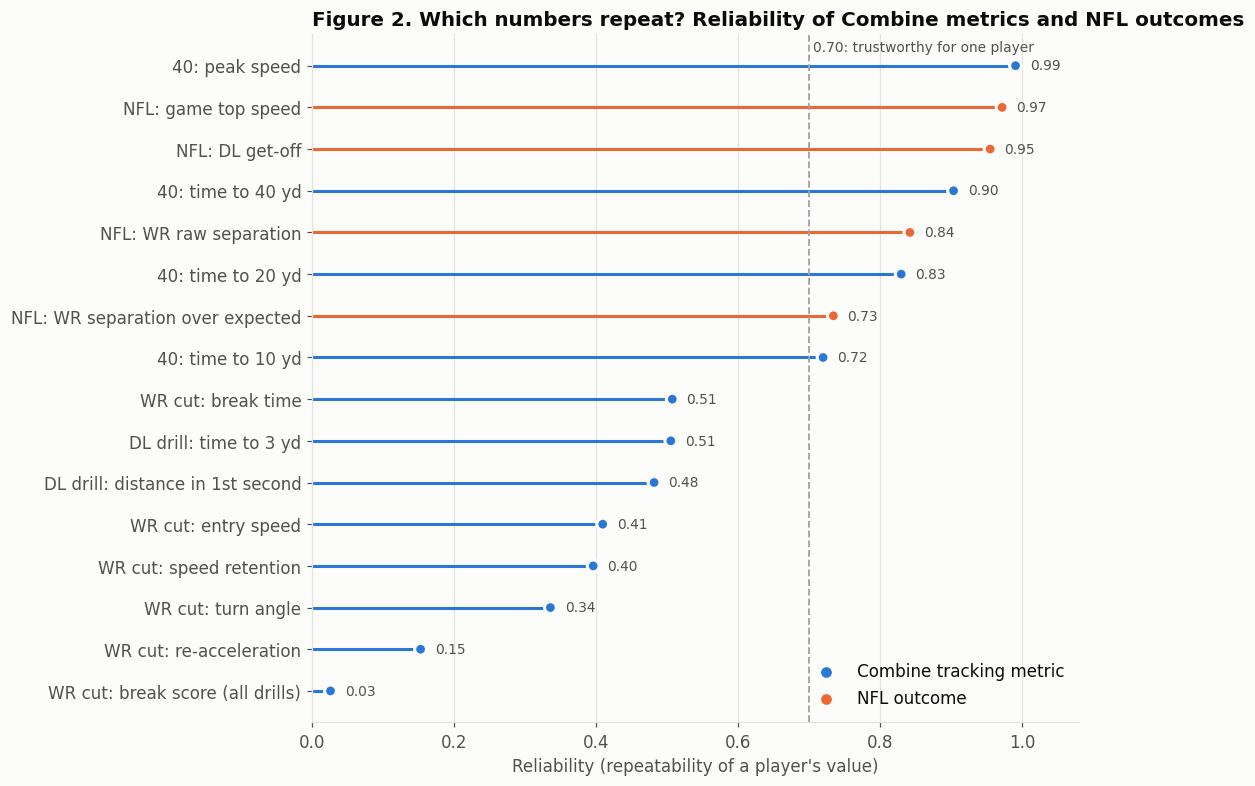

Table 1. How many reps a scout needs before a tracking metric is trustworthy (reliability 0.70)


,measure,pairs,single_rep_r,reps_for_0_70
0,40: peak speed,375,0.98,1
1,40: time to 40 yd,259,0.82,1
2,40: time to 20 yd,375,0.71,1
3,40: time to 10 yd,375,0.56,2
7,WR cut: break time,63,0.51,3
8,WR cut: entry speed,64,0.41,4
9,WR cut: speed retention,64,0.40,4
5,DL drill: time to 3 yd,106,0.34,5
10,WR cut: turn angle,64,0.34,5
4,DL drill: distance in 1st second,106,0.32,6


In [7]:
rel = pd.DataFrame(RELIABILITY).dropna(subset=["reliability"]).sort_values("reliability")
fig, ax = plt.subplots(figsize=(9, 0.42 * len(rel) + 1.4))
colors = rel["side"].map({"Combine": COL["combine"], "NFL": COL["nfl"]})
ax.hlines(range(len(rel)), 0, rel["reliability"].clip(lower=0), color=colors, linewidth=2)
ax.scatter(rel["reliability"].clip(lower=0), range(len(rel)), color=colors, s=60, zorder=3,
           edgecolor=COL["surface"], linewidth=2)
for i, v in enumerate(rel["reliability"]):
    ax.text(max(v, 0) + 0.02, i, f"{v:.2f}", va="center", fontsize=9, color=COL["ink2"])
ax.axvline(0.7, color=COL["ref"], linestyle="--", linewidth=1.2)
ax.text(0.705, len(rel) - 0.4, "0.70: trustworthy for one player", fontsize=9, color=COL["ink2"], va="top")
ax.set_yticks(range(len(rel)), rel["measure"])
ax.set_xlim(0, 1.08); ax.set_xlabel("Reliability (repeatability of a player's value)")
ax.grid(axis="y", visible=False)
ax.scatter([], [], color=COL["combine"], label="Combine tracking metric")
ax.scatter([], [], color=COL["nfl"], label="NFL outcome")
ax.legend(loc="lower right", frameon=False)
ax.set_title("Figure 2. Which numbers repeat? Reliability of Combine metrics and NFL outcomes")
plt.savefig(f"{OUT_DIR}/fig2_reliability_atlas.png"); plt.show()

reps = (pd.DataFrame(RELIABILITY).dropna(subset=["single_rep_r"])
          .assign(reps_for_0_70=lambda d: d["single_rep_r"].apply(
              lambda r: "not repeatable" if not r > 0.05 else str(int(max(1, np.ceil(reps_needed(r)))))))
          [["measure", "pairs", "single_rep_r", "reps_for_0_70"]].sort_values("single_rep_r", ascending=False))
reps["single_rep_r"] = reps["single_rep_r"].round(2)
print("Table 1. How many reps a scout needs before a tracking metric is trustworthy (reliability 0.70)")
reps.to_csv(f"{OUT_DIR}/table1_reps_needed.csv", index=False)
reps

## R2. The positive case: 40-yard peak speed vs the stopwatch

If reliability is the bottleneck, the most reliable tracking metric should be the one that translates. We compare three models of NFL game top speed (all with position fixed effects):
* **Stopwatch:** official 40 time + weight
* **Tracking:** Combine peak speed + weight
* **Both**

We report in-sample R², AIC and **10-fold cross-validated R²**, then repeat the comparison inside each position group.

In [8]:
m = (game.merge(f40, on="nfl_id")
         .merge(combine[["nfl_id", "forty", "combine_weight", "combine_position"]], on="nfl_id")
         .dropna(subset=["forty", "peak_speed", "combine_weight"]).reset_index(drop=True))
m["game_mph"] = m["game_top"] * YDS_TO_MPH
m["peak_mph"] = m["peak_speed"] * YDS_TO_MPH
for c in ["forty", "peak_speed", "combine_weight"]:
    m[c + "_z"] = (m[c] - m[c].mean()) / m[c].std()

forms = {"Stopwatch (40 time)": "game_mph ~ forty_z + combine_weight_z + C(combine_position)",
         "Tracking (peak speed)": "game_mph ~ peak_speed_z + combine_weight_z + C(combine_position)",
         "Both": "game_mph ~ forty_z + peak_speed_z + combine_weight_z + C(combine_position)"}
rng = np.random.default_rng(SEED)
fold = rng.integers(0, 10, len(m))
rows = []
for name, fml in forms.items():
    full = smf.ols(fml, data=m).fit()
    pred = np.empty(len(m))
    for k in range(10):
        pred[fold == k] = smf.ols(fml, data=m[fold != k]).fit().predict(m[fold == k])
    cv_r2 = 1 - np.sum((m["game_mph"] - pred) ** 2) / np.sum((m["game_mph"] - m["game_mph"].mean()) ** 2)
    rows.append({"model": name, "R2": full.rsquared, "AIC": full.aic, "CV_R2": cv_r2})
model_table = pd.DataFrame(rows).round(3)
print(model_table.to_string(index=False))
both = smf.ols(forms["Both"], data=m).fit()
print(both.summary().tables[1])
RESULTS["model_table"] = model_table.to_dict("records")
RESULTS["both_model_p"] = {"forty": round(both.pvalues["forty_z"], 4), "peak_speed": round(both.pvalues["peak_speed_z"], 4)}

pos_rows = []
for pos, g in m.groupby("combine_position"):
    if len(g) < 15:
        continue
    gz = g.assign(fz=(g["forty"] - g["forty"].mean()) / g["forty"].std(),
                  pz=(g["peak_speed"] - g["peak_speed"].mean()) / g["peak_speed"].std())
    add = smf.ols("game_mph ~ fz + pz", data=gz).fit()
    pos_rows.append({"position": pos, "n": len(g),
                     "r_forty": stats.spearmanr(-g["forty"], g["game_mph"])[0],
                     "r_peak": stats.spearmanr(g["peak_speed"], g["game_mph"])[0],
                     "peak_beyond_40_mph_per_sd": add.params["pz"], "p_beyond_40": add.pvalues["pz"]})
pos_table = pd.DataFrame(pos_rows).round(3)
RESULTS["position_table"] = pos_table.to_dict("records")
pos_table

                model    R2      AIC  CV_R2
  Stopwatch (40 time) 0.856 1031.694  0.850
Tracking (peak speed) 0.860 1023.280  0.854
                 Both 0.860 1024.431  0.853
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
Intercept                    17.9378      0.215     83.315      0.000      17.514      18.361
C(combine_position)[T.DL]    -1.8504      0.350     -5.293      0.000      -2.538      -1.163
C(combine_position)[T.OL]    -3.0612      0.430     -7.116      0.000      -3.908      -2.215
C(combine_position)[T.TE]    -0.6733      0.333     -2.023      0.044      -1.328      -0.018
C(combine_position)[T.WR]     0.3826      0.179      2.143      0.033       0.031       0.734
forty_z                      -0.3190      0.350     -0.911      0.363      -1.008       0.370
peak_speed_z                  0.9566      0.316      3.028      0.003   

,position,n,r_forty,r_peak,peak_beyond_40_mph_per_sd,p_beyond_40
0,DB,86,0.315,0.328,0.189,0.295
1,DL,77,0.718,0.699,0.312,0.633
2,OL,84,0.321,0.371,0.978,0.011
3,TE,20,0.464,0.498,0.046,0.920
4,WR,69,0.476,0.530,0.256,0.088


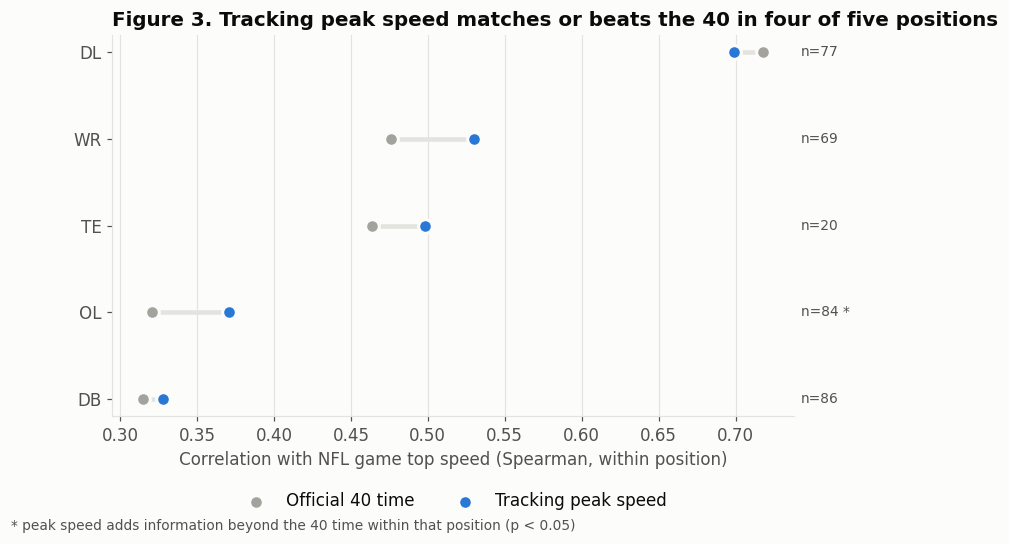

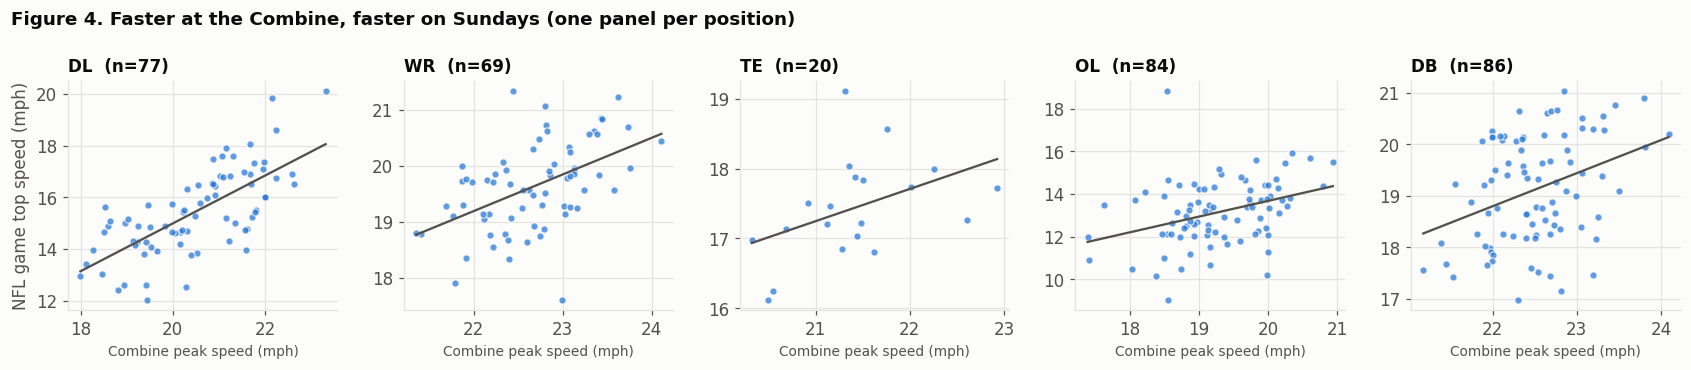

In [9]:
# Figure 3: within-position correlation, 40 time vs tracking peak speed (dumbbell)
pt = pos_table.sort_values("r_peak")
fig, ax = plt.subplots(figsize=(8, 0.6 * len(pt) + 1.5))
y = np.arange(len(pt))
ax.hlines(y, pt["r_forty"], pt["r_peak"], color=COL["grid"], linewidth=3)
ax.scatter(pt["r_forty"], y, color=COL["ref"], s=80, zorder=3, edgecolor=COL["surface"], linewidth=2, label="Official 40 time")
ax.scatter(pt["r_peak"], y, color=COL["combine"], s=80, zorder=3, edgecolor=COL["surface"], linewidth=2, label="Tracking peak speed")
for yi, (_, r) in zip(y, pt.iterrows()):
    star = " *" if r["p_beyond_40"] < 0.05 else ""
    ax.text(1.01, yi, f"n={int(r['n'])}{star}", va="center", fontsize=9, color=COL["ink2"],
            transform=ax.get_yaxis_transform())
ax.set_yticks(y, pt["position"])
ax.set_xlabel("Correlation with NFL game top speed (Spearman, within position)")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False)
ax.set_title("Figure 3. Tracking peak speed matches or beats the 40 in four of five positions")
fig.text(0.01, -0.12, "* peak speed adds information beyond the 40 time within that position (p < 0.05)",
         fontsize=9, color=COL["ink2"])
plt.savefig(f"{OUT_DIR}/fig3_forty_vs_peak_by_position.png"); plt.show()

# Figure 4: Combine peak speed vs NFL game top speed, one panel per position
pos_order = list(pt.sort_values("r_peak", ascending=False)["position"])
fig, axes = plt.subplots(1, len(pos_order), figsize=(3.1 * len(pos_order), 3.4), sharey=False)
axes = np.atleast_1d(axes)
for ax, pos in zip(axes, pos_order):
    g = m[m["combine_position"] == pos]
    ax.scatter(g["peak_mph"], g["game_mph"], s=22, color=COL["combine"], alpha=0.75, edgecolor=COL["surface"], linewidth=0.8)
    b = np.polyfit(g["peak_mph"], g["game_mph"], 1)
    xs = np.linspace(g["peak_mph"].min(), g["peak_mph"].max(), 20)
    ax.plot(xs, np.polyval(b, xs), color=COL["ink2"], linewidth=1.5)
    ax.set_title(f"{pos}  (n={len(g)})", fontsize=11)
    ax.set_xlabel("Combine peak speed (mph)", fontsize=9)
axes[0].set_ylabel("NFL game top speed (mph)")
fig.suptitle("Figure 4. Faster at the Combine, faster on Sundays (one panel per position)",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig4_peak_vs_game_speed.png"); plt.show()

## R3. Why some links fail: the reliability ceiling

A correlation between two measurements can never exceed **√(reliability₁ × reliability₂)**. For each link we plot the observed correlation (with its 95 % bootstrap interval) against that ceiling. A null result sitting under a low ceiling means **the Combine measurement is too noisy to show anything**, not that the trait doesn't matter. A null result under a **high** ceiling is different: the Combine metric is repeatable, so the drill is simply **measuring something other than the NFL skill**.

                          link   n     r     lo    hi  ceiling
  DL drill burst → NFL get-off 103 0.028 -0.161 0.229    0.678
 WR cut skill → NFL separation  99 0.038 -0.155 0.223    0.138
40 peak speed → NFL game speed 336 0.470  0.384 0.552    0.981


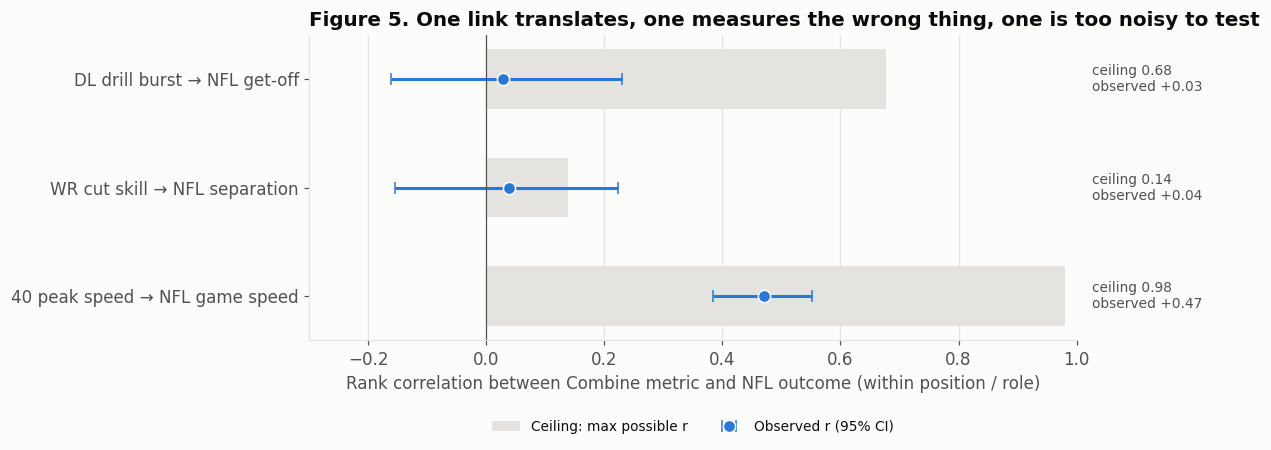

In [10]:
# add the peak-speed link (within-position z-scores)
mz = m.assign(pz=z_within(m, "peak_speed", "combine_position"), gz=z_within(m, "game_mph", "combine_position")).dropna(subset=["pz", "gz"])
r, lo, hi = boot_r(mz["pz"], mz["gz"])
rel_peak = [x["reliability"] for x in RELIABILITY if x["measure"] == "40: peak speed"][0]
LINKS.append({"link": "40 peak speed → NFL game speed", "n": len(mz), "r": r, "lo": lo, "hi": hi,
              "ceiling": np.sqrt(max(rel_peak, 0) * max(rel_gs, 0))})
links = pd.DataFrame(LINKS)
RESULTS["links"] = links.round(3).to_dict("records")
print(links.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(links))[::-1]
ax.barh(y, links["ceiling"], color=COL["grid"], height=0.55, label="Ceiling: max possible r")
ax.errorbar(links["r"], y, xerr=[links["r"] - links["lo"], links["hi"] - links["r"]], fmt="o",
            color=COL["combine"], ecolor=COL["combine"], elinewidth=2, capsize=4, markersize=8,
            markeredgecolor=COL["surface"], label="Observed r (95% CI)")
for yi, (_, r) in zip(y, links.iterrows()):
    ax.text(1.02, yi, f"ceiling {r['ceiling']:.2f}\nobserved {r['r']:+.2f}", va="center", ha="left", fontsize=9,
            color=COL["ink2"], transform=ax.get_yaxis_transform())
ax.axvline(0, color=COL["ink2"], linewidth=0.8)
ax.set_yticks(y, links["link"])
ax.set_xlim(min(-0.3, links["lo"].min() - 0.05), 1.0)
ax.set_xlabel("Rank correlation between Combine metric and NFL outcome (within position / role)")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False, fontsize=9)
ax.set_title("Figure 5. One link translates, one measures the wrong thing, one is too noisy to test")
plt.savefig(f"{OUT_DIR}/fig5_reliability_ceiling.png"); plt.show()

## R4. Figure 1: what the sensor sees

One 40-yard rep (speed over time) and one breaking-route rep (path coloured by speed, with the detected cut). These illustrate the metrics used above.

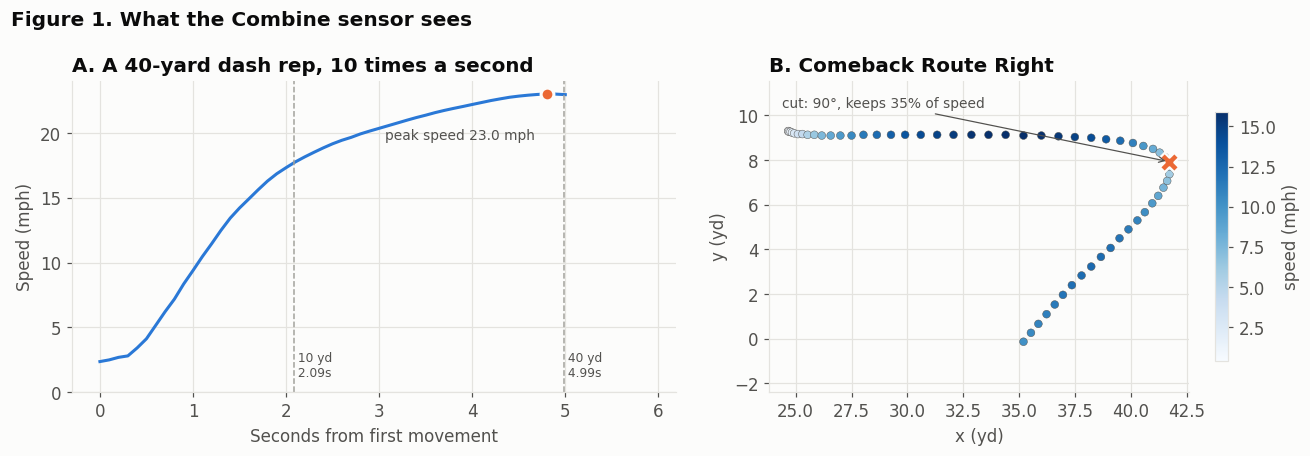

In [11]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.15, 1]})
# panel A: median-ish 40 rep
pick = frep.dropna(subset=["t_40"]).iloc[(frep.dropna(subset=["t_40"])["t_40"] - frep["t_40"].median()).abs().argsort().iloc[0]]
g = f[(f["nfl_id"] == pick["nfl_id"]) & (f["event_id"] == pick["event_id"]) & (f["attempt"] == pick["attempt"])]
sec = (g["time"] - g["time"].iloc[0]).dt.total_seconds().to_numpy()
s = g["s"].to_numpy(); i0 = np.where(s > 0.5)[0][0]
tt = sec - sec[i0]
a1.plot(tt, s * YDS_TO_MPH, color=COL["combine"], linewidth=2)
pk = np.nanargmax(np.where((tt >= 0) & (tt <= pick["t_40"]), s, np.nan))
a1.scatter(tt[pk], s[pk] * YDS_TO_MPH, color=COL["nfl"], s=70, zorder=3, edgecolor=COL["surface"], linewidth=2)
a1.annotate(f"peak speed {s[pk]*YDS_TO_MPH:.1f} mph", (tt[pk], s[pk] * YDS_TO_MPH), xytext=(-8, -30),
            textcoords="offset points", fontsize=9, color=COL["ink2"], ha="right")
for col, lab in [("t_10", "10 yd"), ("t_40", "40 yd")]:
    a1.axvline(pick[col], color=COL["ref"], linestyle="--", linewidth=1)
    a1.text(pick[col], 1, f" {lab}\n {pick[col]:.2f}s", fontsize=8, color=COL["ink2"], va="bottom")
a1.set_xlim(-0.3, pick["t_40"] + 1.2); a1.set_ylim(0, None)
a1.set_xlabel("Seconds from first movement"); a1.set_ylabel("Speed (mph)")
a1.set_title("A. A 40-yard dash rep, 10 times a second")
# panel B: a breaking route rep
wr_pick = wr_rep.iloc[(wr_rep["turn_deg"] - 90).abs().argsort().iloc[0]]
g = t_wr[(t_wr["nfl_id"] == wr_pick["nfl_id"]) & (t_wr["event_id"] == wr_pick["event_id"])
         & (t_wr["attempt"] == wr_pick["attempt"])].reset_index(drop=True)
sc = a2.scatter(g["x"], g["y"], c=g["s"] * YDS_TO_MPH, cmap="Blues", s=26, edgecolor=COL["ink2"], linewidth=0.3)
bf = int(wr_pick["break_frame"])
a2.scatter(g.loc[bf, "x"], g.loc[bf, "y"], marker="X", color=COL["nfl"], s=160, edgecolor=COL["surface"], linewidth=1.5, zorder=3)
a2.annotate(f"cut: {wr_pick['turn_deg']:.0f}°, keeps {wr_pick['speed_retention']:.0%} of speed",
            (g.loc[bf, "x"], g.loc[bf, "y"]), xytext=(0.03, 0.95), textcoords="axes fraction", fontsize=9,
            color=COL["ink2"], va="top", arrowprops=dict(arrowstyle="->", color=COL["ink2"], lw=0.8))
a2.set_aspect("equal", adjustable="datalim"); a2.set_xlabel("x (yd)"); a2.set_ylabel("y (yd)")
a2.set_title(f"B. {wr_pick['drill_name'].replace('_', ' ').title()}")
fig.colorbar(sc, ax=a2, label="speed (mph)", shrink=0.8)
fig.suptitle("Figure 1. What the Combine sensor sees", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig1_what_the_sensor_sees.png"); plt.show()

## Appendix A. Why a naive "all drills" model misleads

Drill names and drill menus change between Combine years. Any feature built by pooling across drills (number of drills run, number of attempts, average rep duration) partly encodes **draft year**. Draft year in turn drives career totals (a 2023 draftee has had three seasons; a 2025 draftee one). The table lists drills that do not appear in all three years.

In [12]:
yr_tab = pd.crosstab(trk["drill_name"], trk["draft_year"])
yr_tab[(yr_tab > 0).sum(axis=1) < yr_tab.shape[1]]

draft_year,2023,2024,2025
drill_name,,,
CIRCUS_ROUTE_LEFT,0,0,2551
END_ZONE_FADE_RIGHT,0,662,814
FOUR_BAG_SHUFFLE_DRILL,365,0,0
LINE,3552,0,0
LINE_DRILL,0,6729,5166
OVER_THE_SHOULDER_ADJUST,762,0,0
PASS_PRO-MIRROR_DRILL,0,3964,3056
PASS_PRO_MIRROR_DRILL,3401,0,0
POST_CORNER_ROUTE_LEFT,2190,2099,0


## Appendix B. Limitations
* **Sample sizes are small** (≈70–120 players per position). Position-level p-values are reported without multiple-comparison correction and should be read as suggestive.
* **Most route drills are run once per player**, so rep-to-rep reliability for cut metrics rests on few repeated pairs.
* **Movement onset** is detected from speed > 0.5 yd/s. The sensor cannot see the exact start the stopwatch uses, which is one reason early-phase times are noisy.
* **NFL outcomes depend on role and opportunity.** Linemen rarely reach top speed in games, and separation depends on scheme. We adjust for position, route, coverage and depth, but not for team or quarterback.
* **Survivorship:** only players with enough NFL snaps or plays enter each link test.

In [13]:
with open(f"{OUT_DIR}/results_summary.json", "w") as fh:
    json.dump({k: v for k, v in RESULTS.items()}, fh, indent=2, default=float)
pd.DataFrame(RELIABILITY).round(3).to_csv(f"{OUT_DIR}/reliability_atlas.csv", index=False)
print("Saved figures and tables to", OUT_DIR)
print(sorted(os.listdir(OUT_DIR)))

Saved figures and tables to /kaggle/working/figs
['fig1_what_the_sensor_sees.png', 'fig2_reliability_atlas.png', 'fig3_forty_vs_peak_by_position.png', 'fig4_peak_vs_game_speed.png', 'fig5_reliability_ceiling.png', 'reliability_atlas.csv', 'results_summary.json', 'table1_reps_needed.csv']
